# OCDM: мультиплексирование ортогональных чирпов

OFDM передаёт $N$ символов на $N$ ортогональных **тонах**. OCDM (Ouyang, Zhao, 2016) — на $N$ ортогональных **чирпах**: линейно-частотно-модулированных сигналах, которые за символ проходят всю полосу. Базис — дискретное **преобразование Френеля** (DFnT):
$$\Phi[m,n]=\frac{e^{-j\pi/4}}{\sqrt N}\,e^{\,j\pi(m-n)^2/N},\qquad s=\Phi^H x .$$
Строка $m$ — один и тот же чирп, сдвинутый во времени на $m$ отсчётов (циклически). Название из оптики: дифракция Френеля описывает, как свет распространяется в ближней зоне, а для периодической решётки картина самовоспроизводится на «длине Тальбота». Дискретная версия — унитарная матрица, такая же удобная, как DFT.

Ключевое разложение:
$$\Phi=F^H\,\Gamma\,F,\qquad\Gamma=\mathrm{diag}\big(e^{-j\pi k^2/N}\big),$$
то есть OCDM = OFDM, у которого каждой поднесущей дали квадратичную фазу и вернулись во время. Отсюда всё остальное: циркулянтный канал (CP + многолучёвость) **коммутирует** с $\Phi$, эквалайзер — одно деление на поднесущую, как у OFDM, а каждый символ размазан по всей полосе, как у одной несущей (SC-FDE).

Связи с серией: LoRa (`lora_sim`) тоже на чирпах, но передаёт **один** чирп из $2^{SF}$ (ортогональная M-арная модуляция: устойчивость ценой скорости). OCDM несёт $N$ чирпов **одновременно** со скоростью OFDM. AFDM (`afdm_sim`) обобщает OCDM, позволяя выбрать наклон чирпа под доплер канала.

1. Базис чирпов и Френель · 2. Канал в области чирпов, OCDM = SC-FDE · 3. BER в многолучевом канале · 4. Помеха в части полосы · 5. Доплер: где OCDM ломается · 6. Пик-фактор

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N = 256                # чирпов (= поднесущих у OFDM-аналога)
FS = 3.84e6            # Δf = f_s/N = 15 кГц
L_CP = 16
PROFILE = "EVA"        # EPA / EVA / ETU, как в lte_sim
SPEED_KMH = 500        # для раздела 4
FC_GHZ = 4.0
BLOCKS = 4000          # блоков на точку BER

rng = np.random.default_rng(SEED)

## Примитивы: матрица Френеля, модем OCDM, каналы 3GPP, частотный MMSE

In [ ]:
n_ = np.arange(N)
F = np.fft.fft(np.eye(N)) / np.sqrt(N)
QPSK = np.array([1 + 1j, -1 + 1j, 1 - 1j, -1 - 1j]) / np.sqrt(2)
GAMMA = np.exp(-1j * np.pi * n_**2 / N)                       # для чётного N
m_, k_ = np.meshgrid(n_, n_, indexing="ij")
PHI = np.exp(-1j * np.pi / 4) / np.sqrt(N) * np.exp(1j * np.pi * (m_ - k_)**2 / N)   # дискретное преобразование Френеля (DFnT)

def crandn(shape, rng):
    return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

def qpsk_bits(B, rng):
    b = rng.integers(0, 2, (B, N, 2))
    return b, QPSK[b[..., 0] + 2 * b[..., 1]]

def hard_bits(z):
    return np.stack([z.real < 0, z.imag < 0], -1).astype(int)

def ocdm_mod(x):
    """s = Φᴴx: сумма N чирпов, символ m — на чирпе, сдвинутом на m отсчётов"""
    return x @ PHI.conj()

def ocdm_demod(y):  
    return y @ PHI.T

PROFILES = {
    "EPA": ([0, 30, 70, 90, 110, 190, 410], [0, -1, -2, -3, -8, -17.2, -20.8]),
    "EVA": ([0, 30, 150, 310, 370, 710, 1090, 1730, 2510], [0, -1.5, -1.4, -3.6, -0.6, -9.1, -7, -12, -16.9]),
    "ETU": ([0, 50, 120, 200, 230, 500, 1600, 2300, 5000], [-1, -1, -1, 0, 0, 0, -3, -5, -7]),
}
def taps(name, rng, B):
    """Рэлеевские лучи с задержками, округлёнными до отсчёта (статичны на блок); возвращает h (B, L_CP)"""
    t, p = PROFILES[name]; p = 10 ** (np.array(p) / 10); p /= p.sum()
    d = np.round(np.array(t) * 1e-9 * FS).astype(int)
    h = np.zeros((B, L_CP), complex)
    for di, pi in zip(d, p):
        h[:, di] += np.sqrt(pi) * crandn(B, rng)
    return h

def through(s, h, n0, rng):
    """CP + циклическая свёртка + шум: в частотной области Y = H·S + W"""
    Hf = np.fft.fft(h, N, axis=-1)
    y = np.fft.ifft(np.fft.fft(s, axis=-1) * Hf, axis=-1) + np.sqrt(n0) * crandn(s.shape, rng)
    return y, Hf

def fde_mmse(y, Hf, n0):
    """одноотводный MMSE в частотной области — общий для OCDM и SC-FDE"""
    return np.fft.ifft(np.fft.fft(y, axis=-1) * np.conj(Hf) / (np.abs(Hf)**2 + n0), axis=-1)

# самопроверки
assert np.allclose(PHI @ PHI.conj().T, np.eye(N)), "Φ unitary"
DEC = F.conj().T @ np.diag(GAMMA) @ F
print(f"Φ = Fᴴ·Γ·F, Γ = diag(e^(−jπk²/N)): max|Φ − FᴴΓF| = {np.max(np.abs(PHI - DEC)):.1e}")
_b, _x = qpsk_bits(3, rng)
assert np.allclose(ocdm_demod(ocdm_mod(_x)), _x)
print(f"N = {N}, f_s = {FS/1e6:.2f} МГц, CP = {L_CP} отсч. = {L_CP/FS*1e6:.1f} мкс")

Φ = Fᴴ·Γ·F, Γ = diag(e^(−jπk²/N)): max|Φ − FᴴΓF| = 7.0e-15
N = 256, f_s = 3.84 МГц, CP = 16 отсч. = 4.2 мкс


## 1. Базис чирпов и Френель
Слева — мгновенная частота трёх базисных функций: прямые с одним наклоном $\Delta f^2$, сдвинутые во времени на $m$ отсчётов. Каждая проходит всю полосу $N\Delta f$ за символ и заворачивается по модулю полосы (дискретный сигнал периодичен по частоте). Посередине — сама функция: частота линейно растёт. Справа — матрица Грама: базис ортонормирован до машинной точности. Разложение $\Phi=F^H\Gamma F$ проверено в ячейке примитивов.

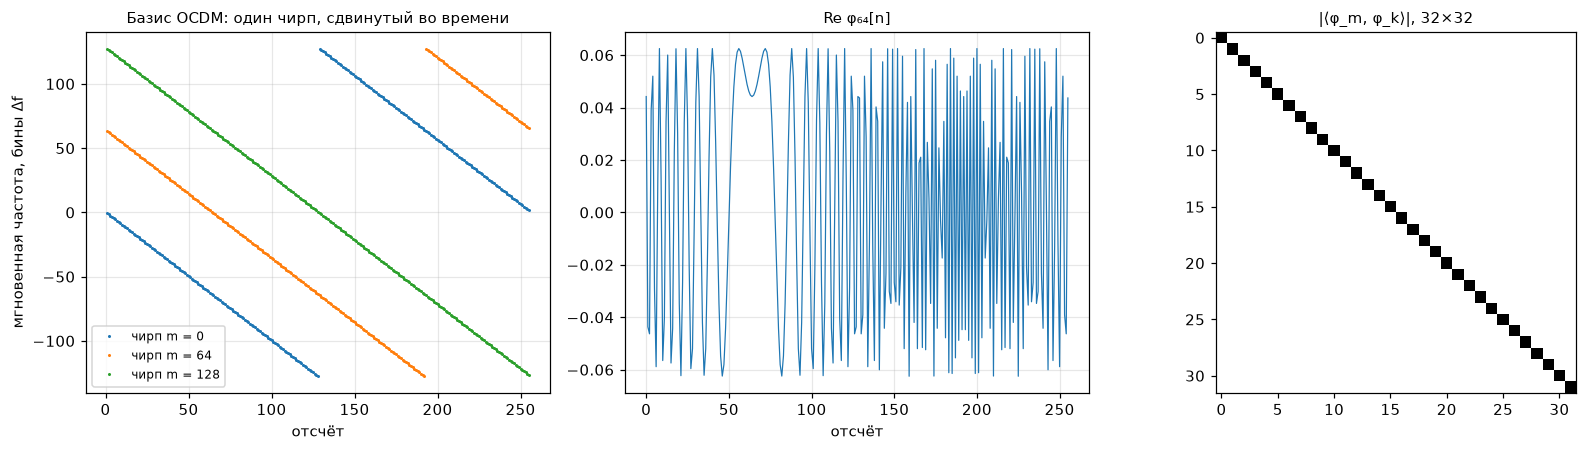

Ортогональность: max|⟨φ_m, φ_k⟩ − δ_mk| = 1.1e-14
Каждый чирп проходит всю полосу N·Δf = 3.84 МГц за N/f_s = 66.7 мкс: наклон Δf² = 0.225 ГГц/с


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for m in (0, 64, 128):
    c = PHI.conj()[m]
    inst = np.diff(np.unwrap(np.angle(c))) / (2 * np.pi) * N
    ax[0].plot(n_[1:], (inst + N / 2) % N - N / 2, ".", ms=2, label=f"чирп m = {m}")
ax[0].set_xlabel("отсчёт"); ax[0].set_ylabel("мгновенная частота, бины Δf"); ax[0].legend(fontsize=8)
ax[0].set_title("Базис OCDM: один чирп, сдвинутый во времени", fontsize=10)
ax[1].plot(n_, PHI.conj()[64].real, lw=0.8)
ax[1].set_xlabel("отсчёт"); ax[1].set_title("Re φ₆₄[n]", fontsize=10)
G = PHI.conj() @ PHI.T
ax[2].imshow(np.abs(G[:32, :32]), cmap="Greys"); ax[2].set_title("|⟨φ_m, φ_k⟩|, 32×32", fontsize=10); ax[2].grid(False)
plt.tight_layout(); plt.show()
print(f"Ортогональность: max|⟨φ_m, φ_k⟩ − δ_mk| = {np.max(np.abs(G - np.eye(N))):.1e}")
print(f"Каждый чирп проходит всю полосу N·Δf = {FS/1e6:.2f} МГц за N/f_s = {N/FS*1e6:.1f} мкс: наклон Δf² = {(FS/N)**2/1e9:.3f} ГГц/с")

## 2. Канал в области чирпов: OCDM = SC-FDE с унитарным прекодером
С CP многолучевой канал — циркулянт $H=F^H\Lambda F$. Так как $\Phi=F^H\Gamma F$ и диагональные $\Gamma,\Lambda$ коммутируют,
$$\Phi H\Phi^H=F^H\Gamma\Lambda\Gamma^HF=F^H\Lambda F=H .$$
В области чирпов канал **тот же циркулянт**: задержка на $l$ отсчётов просто переводит чирп $m$ в чирп $m+l$. Приёмник — частотный эквалайзер, как у SC-FDE: $\hat x=\Phi F^H\frac{\Lambda^*}{|\Lambda|^2+N_0}Fr$.

Отсюда точное утверждение. Ковариация ошибки после MMSE у OCDM $\Phi(F^HDF)\Phi^H=F^HDF$ — **та же**, что у SC-FDE, $D=\mathrm{diag}\big(N_0/(|\Lambda_k|^2+N_0)\big)$. У OFDM ошибка символа $k$ равна $D_k$: на поднесущей в провале — почти 1, на хорошей — почти 0. У OCDM и SC-FDE каждый символ получает **среднее** $\frac1N\sum_kD_k$. В этом и состоит частотное разнесение без кода.

Канал в области чирпов Φ·H·Φᴴ совпадает с самим H (циркулянты коммутируют с Φ = FᴴΓF): max|Φ H Φᴴ − H| = 1.4e-14


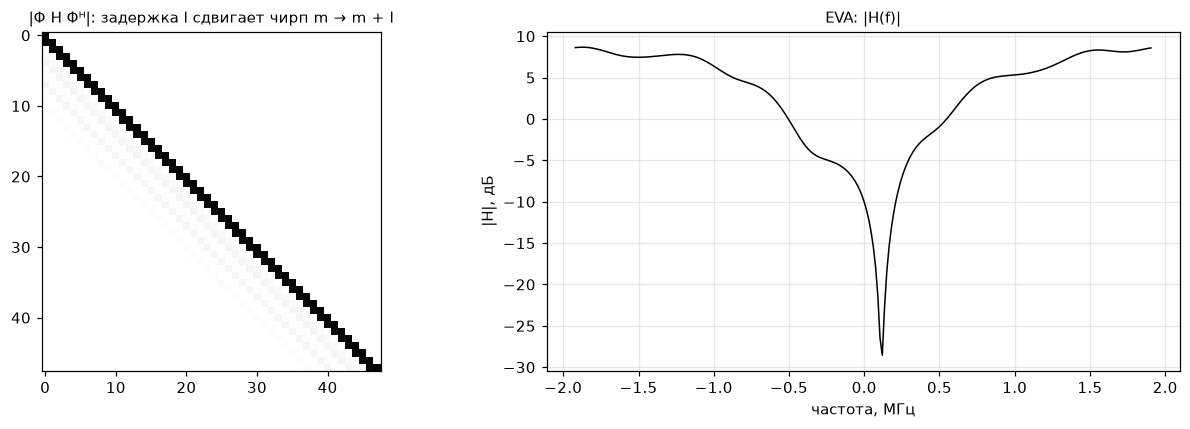

Ковариация ошибки MMSE: OCDM Φ(FᴴDF)Φᴴ против SC-FDE FᴴDF: max разница 1.5e-15; у OFDM дисперсия ошибки — сама диагональ D (от 0.013 до 0.986), у OCDM у всех символов 0.110 = среднее


In [4]:
h = taps(PROFILE, np.random.default_rng(3), 1)[0]
Hc = np.array([np.roll(np.r_[h, np.zeros(N - L_CP)], k) for k in range(N)]).T   # циркулянт: столбец k — h, сдвинутый на k
Hocdm = PHI @ Hc @ PHI.conj().T
print(f"Канал в области чирпов Φ·H·Φᴴ совпадает с самим H (циркулянты коммутируют с Φ = FᴴΓF): max|Φ H Φᴴ − H| = {np.max(np.abs(Hocdm - Hc)):.1e}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].imshow(np.abs(Hocdm[:48, :48]), cmap="Greys"); ax[0].grid(False)
ax[0].set_title("|Φ H Φᴴ|: задержка l сдвигает чирп m → m + l", fontsize=10)
_, x = qpsk_bits(1, rng)
Hf = np.fft.fft(h, N)
ax[1].plot(np.fft.fftshift(np.fft.fftfreq(N, 1 / FS)) / 1e6, 20 * np.log10(np.abs(np.fft.fftshift(Hf))), "k", lw=1)
ax[1].set_xlabel("частота, МГц"); ax[1].set_ylabel("|H|, дБ"); ax[1].set_title(f"{PROFILE}: |H(f)|", fontsize=10)
plt.tight_layout(); plt.show()
# ковариация ошибки после MMSE: у OCDM и SC-FDE одинаковая
n0 = 0.1
D = np.diag(n0 / (np.abs(Hf)**2 + n0))
C_sc = F.conj().T @ D @ F
C_oc = PHI @ C_sc @ PHI.conj().T
print(f"Ковариация ошибки MMSE: OCDM Φ(FᴴDF)Φᴴ против SC-FDE FᴴDF: max разница {np.max(np.abs(C_oc - C_sc)):.1e}; у OFDM дисперсия ошибки — сама диагональ D (от {D.diagonal().real.min():.3f} до {D.diagonal().real.max():.3f}), у OCDM у всех символов {np.real(C_oc[0,0]):.3f} = среднее")

## 3. BER в многолучевом канале
QPSK без кода, EVA, канал статичен на блок. OFDM с одним отводом ложится на теорию Рэлея ($\propto1/\bar\gamma$): каждый символ — одна поднесущая. OCDM и SC-FDE с MMSE совпадают **точка в точку**, как и обещает раздел 2, и идут заметно круче: при 20 дБ на порядок лучше, при 30 дБ ошибок нет. Порядок разнесения ограничен числом независимых кусков полосы ($\sim N\Delta f/B_c$), а линейный MMSE собирает только часть его.

С сильным кодом и перемежением по поднесущим OFDM тоже собирает это разнесение (раздел 8 `lte_sim`), так что преимущество OCDM — в некодированном или слабо кодированном режиме и в более простом выравнивании LLR.

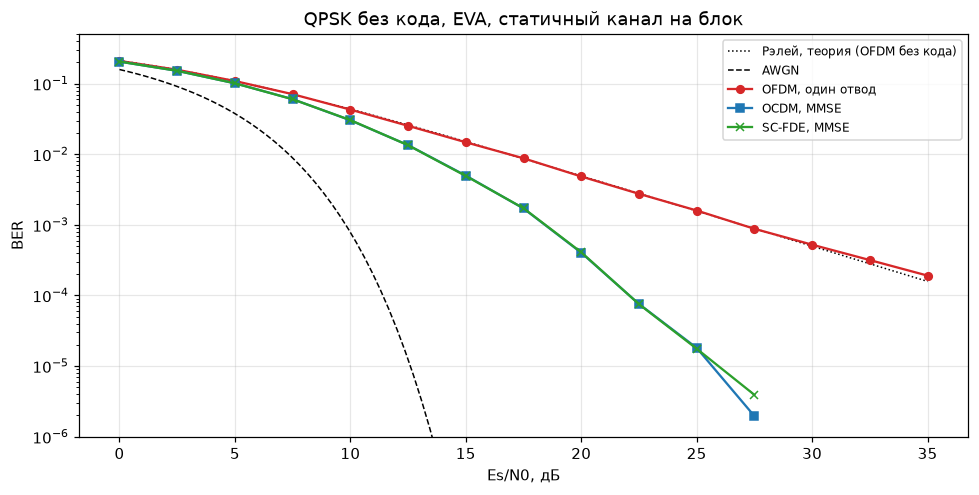

SNR 10 дБ: OFDM 4.3e-02, OCDM 3.0e-02, SC-FDE 3.0e-02
SNR 20 дБ: OFDM 4.8e-03, OCDM 4.0e-04, SC-FDE 4.1e-04
SNR 30 дБ: OFDM 5.2e-04, OCDM 0.0e+00, SC-FDE 0.0e+00


In [5]:
snrs = np.arange(0, 36, 2.5)
ber = {k: [] for k in ("ofdm", "ocdm", "scfde")}
for snr in snrs:
    n0 = 10 ** (-snr / 10)
    b, x = qpsk_bits(BLOCKS, rng); h = taps(PROFILE, rng, BLOCKS)
    y, Hf = through(np.fft.ifft(x, axis=-1) * np.sqrt(N), h, n0, rng)          # OFDM
    ber["ofdm"].append(np.mean(hard_bits(np.fft.fft(y, axis=-1) / np.sqrt(N) / Hf) != b))
    y, Hf = through(ocdm_mod(x), h, n0, rng)
    ber["ocdm"].append(np.mean(hard_bits(ocdm_demod(fde_mmse(y, Hf, n0))) != b))
    y, Hf = through(x, h, n0, rng)                                              # одна несущая + CP
    ber["scfde"].append(np.mean(hard_bits(fde_mmse(y, Hf, n0)) != b))
fig, a = plt.subplots(figsize=(9, 4.6))
sg = np.linspace(0, 35, 100); gg = 10 ** (sg / 10)
a.semilogy(sg, 0.5 * (1 - np.sqrt(gg / 2 / (1 + gg / 2))), "k:", lw=1, label="Рэлей, теория (OFDM без кода)")
a.semilogy(sg, 0.5 * erfc(np.sqrt(gg / 2)), "k--", lw=1, label="AWGN")
for (k, lab), c, mk in zip({"ofdm": "OFDM, один отвод", "ocdm": "OCDM, MMSE", "scfde": "SC-FDE, MMSE"}.items(), ("C3", "C0", "C2"), ("o", "s", "x")):
    v = np.array(ber[k]); ok = v > 0
    a.semilogy(snrs[ok], v[ok], c + mk + "-", ms=5, label=lab)
a.set_ylim(1e-6, 0.5); a.set_xlabel("Es/N0, дБ"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"QPSK без кода, {PROFILE}, статичный канал на блок")
plt.tight_layout(); plt.show()
for i in (4, 8, 12):
    print(f"SNR {snrs[i]:.0f} дБ: OFDM {ber['ofdm'][i]:.1e}, OCDM {ber['ocdm'][i]:.1e}, SC-FDE {ber['scfde'][i]:.1e}")

## 4. Помеха в части полосы
Помеха с суммарной мощностью JSR занимает 10 % поднесущих, канал AWGN, SNR 20 дБ.
- **OFDM**: задетые 10 % символов видят SINR $1/(N_0+\text{JSR}/0.1)$, остальные чистые. BER ≈ $0.1\cdot\text{BER}(\text{SINR})$ и при сильной помехе насыщается на 5 %.
- **OCDM**: унитарное преобразование размазывает помеху по всем символам, SINR = $1/(N_0+\text{JSR})$ у **каждого**.

При слабой помехе (JSR < −6 дБ) выигрывает OCDM: помеха разбавлена. При сильной — OFDM: он жертвует десятой частью символов, а OCDM портит все. С кодом картина ещё сильнее в пользу OFDM: задетые поднесущие с правильными (малыми) LLR — это просто стирания. Расширение без избыточности (rate 1) — **не** CDMA: выигрыша обработки, как в `cdma_sim` и `lora_sim`, здесь нет. Помехоустойчивость покупается только снижением скорости.

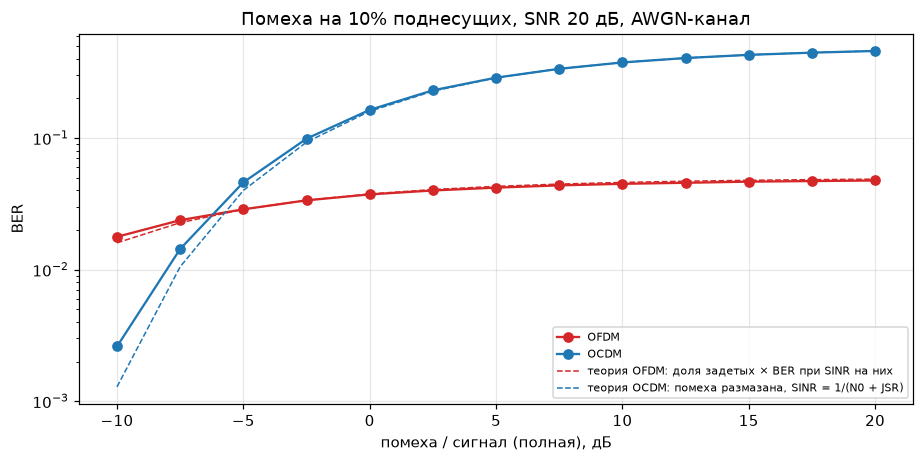

JSR 0 дБ: OFDM 3.7e-02, OCDM 1.6e-01; точка равенства — где BER(1/JSR) = доля·½


In [6]:
# помеха в части полосы: OFDM теряет символы на задетых поднесущих, OCDM размазывает помеху по всем
frac_jam, SNR_J = 0.1, 20
jsr = np.arange(-10, 21, 2.5)
r = {"ofdm": [], "ocdm": []}
for j in jsr:
    n0 = 10 ** (-SNR_J / 10)
    b, x = qpsk_bits(2000, rng)
    J = np.zeros(N); J[rng.choice(N, int(frac_jam * N), replace=False)] = 1
    Pj = 10 ** (j / 10) / frac_jam                               # вся мощность помехи JSR в доле frac_jam полосы
    noise_f = (np.sqrt(n0) + np.sqrt(Pj) * J) * crandn(x.shape, rng)        # шум + помеха на поднесущих
    # OFDM: Y = X + W_f
    r["ofdm"].append(np.mean(hard_bits(x + noise_f) != b))
    # OCDM: символы → Φᴴ → FFT → +W_f → IFFT → Φ; приёмник знает спектр помехи (MMSE-взвешивание не нужно, канал = 1)
    z = ocdm_demod(np.fft.ifft(np.fft.fft(ocdm_mod(x), axis=-1) / np.sqrt(N) + noise_f, axis=-1) * np.sqrt(N))
    r["ocdm"].append(np.mean(hard_bits(z) != b))
fig, a = plt.subplots(figsize=(8.5, 4.3))
for k, c in (("ofdm", "C3"), ("ocdm", "C0")):
    a.semilogy(jsr, r[k], c + "o-", label=k.upper())
th_ofdm = frac_jam * 0.5 * erfc(np.sqrt(0.5 / (10 ** (-SNR_J / 10) + 10 ** (jsr / 10) / frac_jam))) + (1 - frac_jam) * 0.5 * erfc(np.sqrt(0.5 * 10 ** (SNR_J / 10)))
th_ocdm = 0.5 * erfc(np.sqrt(0.5 / (10 ** (-SNR_J / 10) + 10 ** (jsr / 10))))
a.semilogy(jsr, th_ofdm, "C3--", lw=1, label="теория OFDM: доля задетых × BER при SINR на них")
a.semilogy(jsr, th_ocdm, "C0--", lw=1, label="теория OCDM: помеха размазана, SINR = 1/(N0 + JSR)")
a.set_xlabel("помеха / сигнал (полная), дБ"); a.set_ylabel("BER"); a.legend(fontsize=7)
a.set_title(f"Помеха на {frac_jam:.0%} поднесущих, SNR {SNR_J} дБ, AWGN-канал")
plt.tight_layout(); plt.show()
i0 = np.argmin(np.abs(jsr))
print(f"JSR 0 дБ: OFDM {r['ofdm'][i0]:.1e}, OCDM {r['ocdm'][i0]:.1e}; точка равенства — где BER(1/JSR) = доля·½")

## 5. Доплер: где OCDM ломается
С доплером канал перестаёт быть циркулянтом, и $\Phi H\Phi^H\neq H$. Для чирпа с наклоном $\Delta f^2$ сдвиг частоты на $\nu$ эквивалентен сдвигу во времени: доплер $\alpha$ бинов переводит чирп $m$ в $m+\alpha$ — **туда же, куда задержка** $l=\alpha$. Лучи с разными $(l,\alpha)$, но одинаковым $l+\alpha$, складываются в один отсчёт и теряют разнесение. Это связь задержки и доплера, знакомая по LoRa (там она мешает синхронизации, раздел 3 `lora_sim`).

- **OCDM с частотным эквалайзером** (как будто канал статичен) — пол ошибок от межчирповой интерференции, как у OFDM от ICI.
- **OCDM с полным LMMSE** по матрице канала — пол уходит, кривая крутая: разнесение по лучам ещё в основном собирается, но столкновения $l+\alpha$ отнимают часть.

AFDM (следующий ноутбук) выбирает наклон $c_1$ так, чтобы $\alpha+2Nc_1\,l$ никогда не совпадали. Тогда каждый луч занимает свои отсчёты, и разнесение полное.

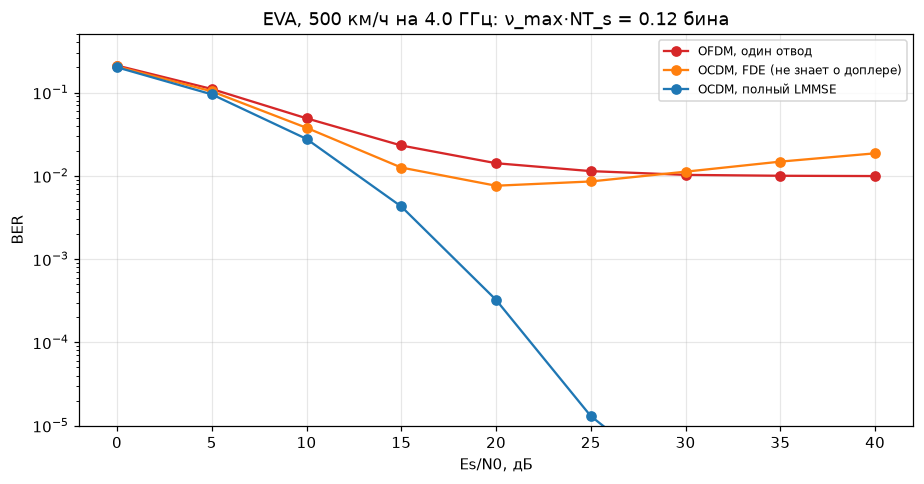

ofdm     : BER при 20 / 30 / 40 дБ = 1.4e-02 / 1.0e-02 / 9.9e-03
ocdm     : BER при 20 / 30 / 40 дБ = 3.2e-04 / 1.6e-06 / 0.0e+00
ocdm_fde : BER при 20 / 30 / 40 дБ = 7.6e-03 / 1.1e-02 / 1.9e-02


In [7]:
# доплер: время-переменный канал, лучи EVA с доплером ν_max·cos θ
NU_MAX = SPEED_KMH / 3.6 * FC_GHZ * 1e9 / 3e8
def tv_matrix(rng, name=PROFILE):
    """матрица N×N «отправленный блок → принятый» с CP, каждый луч со своим доплером"""
    t, p = PROFILES[name]; p = 10 ** (np.array(p) / 10); p /= p.sum()
    d = np.round(np.array(t) * 1e-9 * FS).astype(int)
    Hm = np.zeros((N, N), complex)
    for di, pi in zip(d, p):
        nu = NU_MAX * np.cos(rng.uniform(0, 2 * np.pi)); g = np.sqrt(pi) * crandn((), rng)
        Hm += g * np.diag(np.exp(2j * np.pi * nu * (n_ + L_CP) / FS)) @ np.roll(np.eye(N), di, 0)
    return Hm
snrs5 = np.arange(0, 41, 5); R = 300
r5 = {k: np.zeros(len(snrs5)) for k in ("ofdm", "ocdm", "ocdm_fde")}
for _ in range(R):
    Hm = tv_matrix(rng)
    Ho = F @ Hm @ F.conj().T; Hc = PHI @ Hm @ PHI.conj().T
    b, x = qpsk_bits(4, rng)
    for i, snr in enumerate(snrs5):
        n0 = 10 ** (-snr / 10)
        w = np.sqrt(n0) * crandn(x.shape, rng)
        yo = x @ Ho.T + w
        r5["ofdm"][i] += np.mean(hard_bits(yo / np.diag(Ho)) != b)
        yc = x @ Hc.T + w
        z = np.linalg.solve(Hc.conj().T @ Hc + n0 * np.eye(N), Hc.conj().T @ yc.T).T
        r5["ocdm"][i] += np.mean(hard_bits(z) != b)
        Hf = np.diag(Ho)                                         # «как будто канал статичен»: FDE по диагонали
        zf = (yc @ PHI.conj()) @ F.T                              # в частоту
        r5["ocdm_fde"][i] += np.mean(hard_bits(((zf * np.conj(Hf) / (np.abs(Hf)**2 + n0)) @ F.conj().T) @ PHI.T) != b)
r5 = {k: v / R for k, v in r5.items()}
fig, a = plt.subplots(figsize=(8.5, 4.5))
for (k, lab), c in zip({"ofdm": "OFDM, один отвод", "ocdm_fde": "OCDM, FDE (не знает о доплере)", "ocdm": "OCDM, полный LMMSE"}.items(), ("C3", "C1", "C0")):
    ok = r5[k] > 0
    a.semilogy(snrs5[ok], r5[k][ok], c + "o-", label=lab)
a.set_ylim(1e-5, 0.5); a.set_xlabel("Es/N0, дБ"); a.set_ylabel("BER"); a.legend(fontsize=8)
a.set_title(f"{PROFILE}, {SPEED_KMH} км/ч на {FC_GHZ} ГГц: ν_max·NT_s = {NU_MAX*N/FS:.2f} бина")
plt.tight_layout(); plt.show()
for k in r5:
    print(f"{k:9}: BER при 20 / 30 / 40 дБ = {r5[k][4]:.1e} / {r5[k][6]:.1e} / {r5[k][8]:.1e}")

## 6. Пик-фактор
OCDM — сумма $N$ чирпов со случайными фазами, гауссова по ЦПТ: пик-фактор как у OFDM (~11 дБ при 0.1 %). Одна несущая (SC-FDE) — на 3–4 дБ ниже. Поэтому на аплинке, где важен КПД усилителя, SC-FDE/SC-FDMA предпочтительнее: при MMSE-приёме они дают **ту же** BER, что OCDM (раздел 3).

OFDM      : PAPR в 0.1 % блоков 11.3 дБ
OCDM      : PAPR в 0.1 % блоков 11.1 дБ


SC (QPSK) : PAPR в 0.1 % блоков 7.7 дБ


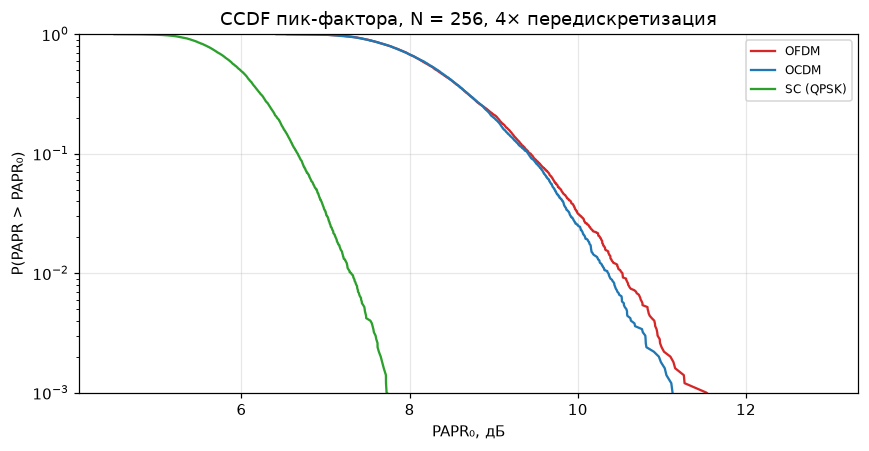

In [8]:
def papr(s):
    p = np.abs(s)**2
    return 10 * np.log10(p.max(-1) / p.mean(-1))
B = 5000; _, x = qpsk_bits(B, rng)
OS = 4
def up(s):
    S = np.fft.fft(s, axis=-1); G = np.zeros((len(s), N * OS), complex)
    G[:, :N // 2] = S[:, :N // 2]; G[:, -N // 2:] = S[:, -N // 2:]
    return np.fft.ifft(G, axis=-1)
fig, a = plt.subplots(figsize=(8, 4.2))
for k, s, c in (("OFDM", np.fft.ifft(x, axis=-1), "C3"), ("OCDM", ocdm_mod(x), "C0"), ("SC (QPSK)", x, "C2")):
    p = np.sort(papr(up(s)))
    a.semilogy(p, 1 - np.arange(B) / B, c, label=k)
    print(f"{k:10}: PAPR в 0.1 % блоков {np.quantile(p, 0.999):.1f} дБ")
a.set_ylim(1e-3, 1); a.set_xlabel("PAPR₀, дБ"); a.set_ylabel("P(PAPR > PAPR₀)"); a.legend(fontsize=8)
a.set_title(f"CCDF пик-фактора, N = {N}, 4× передискретизация")
plt.tight_layout(); plt.show()

## Сравнение: OFDM, SC-FDE, OCDM, LoRa
| | OFDM | SC-FDE | OCDM | LoRa (CSS) |
|---|---|---|---|---|
| Базис | тоны | импульсы (дельты) | чирпы, $\Phi=F^H\Gamma F$ | $2^{SF}$ сдвигов одного чирпа, **один** за символ |
| Скорость | $N$ символов на блок | $N$ | $N$ | $SF$ бит на $2^{SF}$ отсчётов |
| Эквалайзер (статичный канал) | одно деление на поднесущую | частотный MMSE | частотный MMSE (тот же) | не нужен (некогерентный приём) |
| Разнесение без кода | 1 | частотное, через MMSE | **то же, что SC-FDE** | огромный выигрыш обработки |
| Узкополосная помеха | выбивает свои поднесущие | размазана | размазана | подавлена расширением |
| Доплер | ICI | межсимвольная | связь задержки и доплера | смещает символ (CFO = сдвиг) |
| PAPR | гауссов | низкий | гауссов | постоянная огибающая |

OCDM — красивый пример того, что форма волны в канале с CP — это просто унитарный прекодер поверх OFDM, и при линейном приёме значение имеет только то, как он «перемешивает» поднесущие. Чирпы здесь ничем не лучше одной несущей, пока нет доплера. Интересной OCDM становится в двукратно-рассеивающем канале и в радаре (чирп — классический радарный импульс). Именно туда её обобщает AFDM.

## Что покрутить
- `PROFILE = "EPA"` — полоса когерентности шире, разнесения меньше: кривые OCDM и OFDM в разделе 3 сближаются; `"ETU"` — расходятся сильнее
- `N = 64` (та же $f_s$) — меньше независимых кусков полосы, разрыв OCDM/OFDM уменьшается
- в разделе 4 `frac_jam = 0.5` — точка, где OFDM и OCDM меняются местами, сдвигается
- `SPEED_KMH = 120` — в разделе 5 OCDM с частотным эквалайзером почти не страдает: межчирповая помеха падает как $(\nu T)^2$
- в разделе 5 поставить всем лучам один доплер $\alpha$ — лучи с $l+\alpha$, равными у разных путей, сольются, и OCDM LMMSE потеряет наклон